In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


PATH = "/home/fidisroxy/development/house-app/house-pred-app/ml/data/raw/kaggle_london_house_price_data.csv"
df = pd.read_csv(PATH)

sns.set_theme(style="whitegrid")

In [7]:
df.shape

(418201, 28)

In [4]:

df.isnull().sum()

fullAddress                                       0
postcode                                          0
country                                           0
outcode                                           0
latitude                                          0
longitude                                         0
bathrooms                                     77931
bedrooms                                      40536
floorAreaSqM                                  25210
livingRooms                                   60500
tenure                                        11512
propertyType                                   1136
currentEnergyRating                           84526
rentEstimate_lowerPrice                        1741
rentEstimate_currentPrice                      1741
rentEstimate_upperPrice                        1741
saleEstimate_lowerPrice                         640
saleEstimate_currentPrice                       640
saleEstimate_upperPrice                         640
saleEstimate

In [6]:
print(df.head(5))

                                         fullAddress  postcode  country  \
0       Flat 9, 35 Furnival Street, London, EC4A 1JQ  EC4A 1JQ  England   
1       Flat 6, 35 Furnival Street, London, EC4A 1JQ  EC4A 1JQ  England   
2  Flat 35, Octavia House, Medway Street, London,...  SW1P 2TA  England   
3    24 Chester Court, Lomond Grove, London, SE5 7HS   SE5 7HS  England   
4              18 Alexandra Gardens, London, N10 3RL   N10 3RL  England   

  outcode   latitude  longitude  bathrooms  bedrooms  floorAreaSqM  \
0    EC4A  51.517282  -0.110314        1.0       1.0          45.0   
1    EC4A  51.517282  -0.110314        NaN       NaN           NaN   
2    SW1P  51.495505  -0.132379        2.0       2.0          71.0   
3     SE5  51.478185  -0.092201        1.0       1.0          64.0   
4     N10  51.588774  -0.139599        1.0       4.0         137.0   

   livingRooms  ... saleEstimate_upperPrice saleEstimate_confidenceLevel  \
0          1.0  ...                630000.0         

In [7]:
print(df.shape)

(418201, 28)


In [9]:
print(df.dtypes) 

fullAddress                                   object
postcode                                      object
country                                       object
outcode                                       object
latitude                                     float64
longitude                                    float64
bathrooms                                    float64
bedrooms                                     float64
floorAreaSqM                                 float64
livingRooms                                  float64
tenure                                        object
propertyType                                  object
currentEnergyRating                           object
rentEstimate_lowerPrice                      float64
rentEstimate_currentPrice                    float64
rentEstimate_upperPrice                      float64
saleEstimate_lowerPrice                      float64
saleEstimate_currentPrice                    float64
saleEstimate_upperPrice                      f

In [10]:
print(df.describe(include="all")) 

                                              fullAddress  postcode  country  \
count                                              418201    418201   418201   
unique                                             137760     48392        1   
top     74 Western Beach Apartments, 36 Hanover Avenue...  SW1P 3AN  England   
freq                                                  224       366   418201   
mean                                                  NaN       NaN      NaN   
std                                                   NaN       NaN      NaN   
min                                                   NaN       NaN      NaN   
25%                                                   NaN       NaN      NaN   
50%                                                   NaN       NaN      NaN   
75%                                                   NaN       NaN      NaN   
max                                                   NaN       NaN      NaN   

       outcode       latitude      long

In [10]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
}).sort_values("missing_percent", ascending=False)

In [11]:
print(missing_summary)


                                           missing_count  missing_percent
history_numericChange                             180219        43.093871
history_percentageChange                          180219        43.093871
currentEnergyRating                                84526        20.211812
bathrooms                                          77931        18.634819
livingRooms                                        60500        14.466728
bedrooms                                           40536         9.692947
floorAreaSqM                                       25210         6.028202
tenure                                             11512         2.752743
rentEstimate_upperPrice                             1741         0.416307
rentEstimate_lowerPrice                             1741         0.416307
rentEstimate_currentPrice                           1741         0.416307
propertyType                                        1136         0.271640
saleEstimate_upperPrice               

In [14]:
print("Duplicate rows:", df.duplicated().sum())


Duplicate rows: 7


In [10]:

print(df.nunique(dropna=False))

fullAddress                                  137760
postcode                                      48392
country                                           1
outcode                                         168
latitude                                      92247
longitude                                     93060
bathrooms                                        10
bedrooms                                         10
floorAreaSqM                                    492
livingRooms                                      10
tenure                                            5
propertyType                                     20
currentEnergyRating                               8
rentEstimate_lowerPrice                         749
rentEstimate_currentPrice                       808
rentEstimate_upperPrice                         862
saleEstimate_lowerPrice                        5587
saleEstimate_currentPrice                      6153
saleEstimate_upperPrice                        6725
saleEstimate

Univirate Analysis

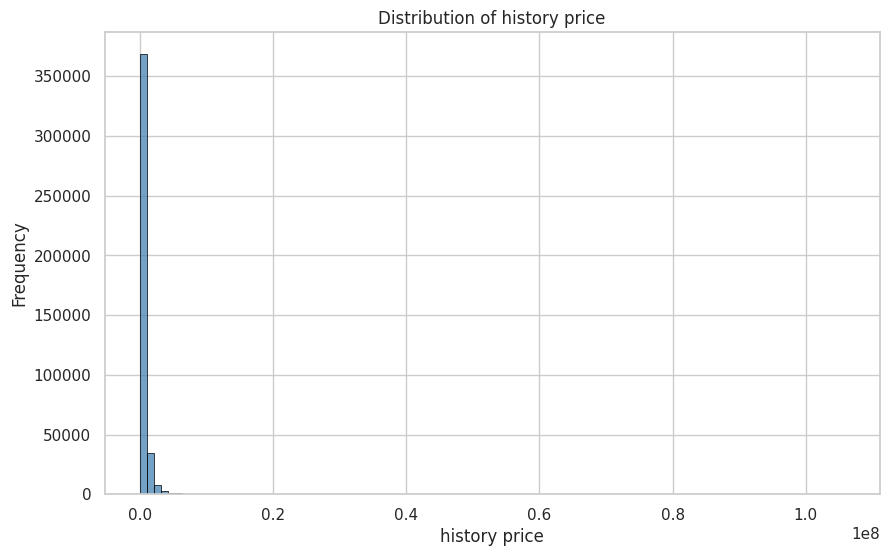

In [23]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="history_price",
    kde=False,
    bins=100,
    color="steelblue",
    edgecolor="black",
    stat="count"
)

plt.title("Distribution of history price")
plt.xlabel("history price")
plt.ylabel("Frequency")

plt.show()

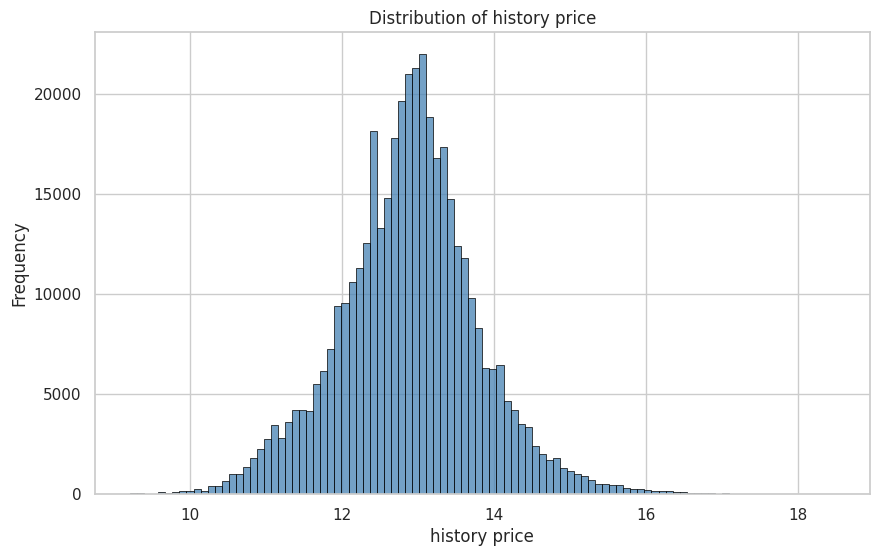

In [25]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="log_history_price",
    kde=False,
    bins=100,
    color="steelblue",
    edgecolor="black",
    stat="count"
)

plt.title("Distribution of history price")
plt.xlabel("history price")
plt.ylabel("Frequency")

plt.show()

In [24]:
df["log_history_price"] = np.log1p(df["history_price"])

In [26]:
print("Original skewness:", df["history_price"].skew())

print("Log skewness:", df["log_history_price"].skew())

Original skewness: 22.49265330621782
Log skewness: 0.12619212794110804


In [27]:
df["history_price"].describe(
    percentiles=[0.5, 0.9, 0.95, 0.99]
)

count    4.182010e+05
mean     6.395840e+05
std      1.327933e+06
min      1.000000e+04
50%      4.000000e+05
90%      1.200000e+06
95%      1.770000e+06
99%      4.500000e+06
max      1.058000e+08
Name: history_price, dtype: float64

In [28]:
df.nlargest(10, "history_price")

,fullAddress,postcode,country,outcode,latitude,longitude,bathrooms,bedrooms,floorAreaSqM,livingRooms,...,saleEstimate_confidenceLevel,saleEstimate_ingestedAt,saleEstimate_valueChange.numericChange,saleEstimate_valueChange.percentageChange,saleEstimate_valueChange.saleDate,history_date,history_price,history_percentageChange,history_numericChange,log_history_price
260712,"201 Isledon Road, London, N7 7JR",N7 7JR,England,N7,51.562612,-0.107353,1.0,1.0,NaN,1.0,...,MEDIUM,2025-02-06T14:05:28.374Z,-105377000.0,-99.600189,2020-05-15,2020-05-15,105800000,NaN,NaN,18.477061
283748,"78 Dance Square, London, EC1V 3AJ",EC1V 3AJ,England,EC1V,51.526163,-0.096698,2.0,3.0,100.0,1.0,...,MEDIUM,2024-10-07T13:26:59.894Z,-99142000.0,-99.142000,2021-06-30,2021-06-30,100000000,NaN,NaN,18.420681
292726,"33 Summerfield Street, London, SE12 0NH",SE12 0NH,England,SE12,51.443218,0.013347,NaN,1.0,45.0,NaN,...,MEDIUM,2024-10-07T13:26:59.894Z,-99003000.0,-99.763196,2021-11-29,2021-11-29,99238058,NaN,NaN,18.413032
207485,"Second Floor Flat, Gloucester House, 149 Old P...",W1K 1QX,England,W1K,51.504063,-0.149219,5.0,4.0,NaN,2.0,...,LOW,2024-10-07T13:26:59.894Z,-9235000.0,-72.716535,2022-11-25,2015-12-02,95900000,NaN,NaN,18.378817
207495,"Second Floor Flat, Gloucester House, 149 Old P...",W1K 1QX,England,W1K,51.504063,-0.149219,5.0,4.0,NaN,2.0,...,LOW,2025-01-10T11:04:57.114Z,-7900000.0,-62.204724,2022-11-25,2015-12-02,95900000,NaN,NaN,18.378817
347420,"Apartment 2608, Riverstone Heights, 18 Reed Av...",E3 3ZF,England,E3,51.525195,-0.010183,1.0,1.0,NaN,NaN,...,LOW,2024-10-07T13:26:59.894Z,-88043000.0,-99.596154,2023-03-28,2023-03-28,88399999,NaN,NaN,18.297383
291394,"Flat 37, 8 Whistler Square, London, SW1W 8BW",SW1W 8BW,England,SW1W,51.489260,-0.154608,NaN,NaN,NaN,NaN,...,LOW,2025-02-06T14:05:28.374Z,-82888000.0,-94.729143,2021-11-09,2021-11-09,87500000,NaN,NaN,18.287149
291415,"Flat 37, 8 Whistler Square, London, SW1W 8BW",SW1W 8BW,England,SW1W,51.489260,-0.154608,NaN,NaN,NaN,NaN,...,LOW,2024-10-07T13:26:59.894Z,-83301000.0,-95.201143,2021-11-09,2021-11-09,87500000,NaN,NaN,18.287149
318537,"15–25 Talbot Square, London, W2 1TT",W2 1TT,England,W2,51.515230,-0.174955,2.0,2.0,NaN,NaN,...,LOW,2025-01-10T11:04:57.114Z,-78475000.0,-98.710692,2022-09-02,2022-09-02,79500000,NaN,NaN,18.191268
348040,"Ambassadors Residence, 24 Belgrave Square, Lon...",SW1X 8QA,England,SW1X,51.497885,-0.153778,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2023-03-31,77500000,NaN,NaN,18.165789


In [30]:
numerical_null_features = df.select_dtypes(
    include="number"
).columns[df.select_dtypes(include="number").isnull().any()]

print(numerical_null_features.tolist())

['bathrooms', 'bedrooms', 'floorAreaSqM', 'livingRooms', 'rentEstimate_lowerPrice', 'rentEstimate_currentPrice', 'rentEstimate_upperPrice', 'saleEstimate_lowerPrice', 'saleEstimate_currentPrice', 'saleEstimate_upperPrice', 'saleEstimate_valueChange.numericChange', 'saleEstimate_valueChange.percentageChange', 'history_percentageChange', 'history_numericChange']


In [ ]:
categorical_null_features = df.select_dtypes(
    include=["object", "category", "string"]
).columns[
    df.select_dtypes(
        include=["object", "category", "string"]
    ).isnull().any()
]

print(categorical_null_features.tolist())

['tenure', 'propertyType', 'currentEnergyRating', 'saleEstimate_confidenceLevel', 'saleEstimate_ingestedAt', 'saleEstimate_valueChange.saleDate']
